Dari Praktikum 1 :

In [ ]:
# Persiapan Lingkungan

# Instalasi pustaka hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

# Membuat fungsi bernama 'plot' untuk menggambar grafik penyebaran data hasil klastering.
# Fungsi ini menerima data (X), kelompok/klaster (labels), tingkat keyakinan (probabilities),
# pengaturan (parameters), apakah ini data asli (ground_truth), dan tempat menggambar (ax).
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    
    # Jika kita belum menyediakan tempat untuk menggambar (kanvas/ax kosong)...
    if ax is None:
        # ...maka buat kanvas baru dengan ukuran panjang 10 dan lebar 4.
        _, ax = plt.subplots(figsize=(10, 4))
        
    # Jika label klaster kosong, anggap semua data bernilai 1 (masuk di satu kelompok yang sama).
    labels = labels if labels is not None else np.ones(X.shape[0])
    
    # Jika nilai peluang/keyakinan kosong, anggap semua nilainya 1 (100% yakin).
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    
    # Mencari tahu ada kelompok (klaster) apa saja di dalam data secara unik tanpa duplikat.
    unique_labels = set(labels)
    
    # Menyiapkan warna yang berbeda-beda dari palet "Spectral" untuk masing-masing kelompok.
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    
    # Membuat daftar/kamus yang memasangkan nomor urut data dengan nilai peluangnya (probabilitas).
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    
    # Memasangkan setiap kelompok dengan warnanya, lalu memprosesnya satu per satu.
    for k, col in zip(unique_labels, colors):
        
        # Di HDBSCAN, label '-1' artinya adalah data noise (data yang tidak masuk kelompok manapun).
        # Jika itu kelompok -1, ubah warnanya menjadi hitam [R, G, B, Alpha] = [0, 0, 0, 1].
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
            
        # Mencari nomor urut data mana saja yang termasuk dalam kelompok 'k' saat ini.
        class_index = (labels == k).nonzero()[0]
        
        # Mulai memproses setiap satu titik data yang ada di dalam kelompok 'k'.
        for ci in class_index:
            
            # Menggambar titik data tersebut ke dalam grafik (kanvas).
            ax.plot(
                X[ci, 0], # Posisi data pada sumbu X (mendatar)
                X[ci, 1], # Posisi data pada sumbu Y (tegak)
                
                # Jika data noise (-1), bentuknya tanda silang ("x"). Kalau bukan, bentuknya bulat ("o").
                "x" if k == -1 else "o", 
                
                # Mewarnai bagian dalam bentuk tersebut dengan warna kelompoknya.
                markerfacecolor=tuple(col),
                
                # Memberi garis tepi berwarna hitam ("k" singkatan dari blacK) pada bentuknya.
                markeredgecolor="k",
                
                # Menentukan ukuran titik. Jika noise, ukurannya tetap 4. 
                # Jika bukan noise, ukurannya membesar sesuai dengan tingkat probabilitas/keyakinannya.
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
            
    # Menghitung total jumlah kelompok/klaster.
    # Dikurangi 1 jika ada label '-1', karena noise (-1) tidak dianggap sebagai kelompok valid.
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    
    # Menyiapkan kata awal untuk judul. 
    # Pakai "True" jika itu jawaban kunci/asli, "Estimated" jika itu tebakan dari mesin (model).
    preamble = "True" if ground_truth else "Estimated"
    
    # Membuat kalimat judul utama, contoh: "Estimated number of clusters: 3"
    title = f"{preamble} number of clusters: {n_clusters_}"
    
    # Jika ada pengaturan/parameter tambahan yang dimasukkan...
    if parameters is not None:
        # ...gabungkan nama-nama pengaturannya menjadi teks...
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        # ...lalu tambahkan teks pengaturan tersebut di belakang judul utama.
        title += f" | {parameters_str}"
        
    # Memasang tulisan judul yang sudah dirangkai tadi ke bagian atas grafik.
    ax.set_title(title)
    
    # Merapikan jarak antar elemen grafik agar pas, rapi, dan tidak ada yang terpotong.
    plt.tight_layout()

# Langkah 3: Membuat Dataset Sintetis

centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)

# Langkah 4: Uji Scale Invariance pada DBSCAN

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

# Perbaiki dengan mengubah eps sesuai skala:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

# Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

# Langkah 6: Multi-Scale Clustering

centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

# Bandingkan DBSCAN dengan eps berbeda:

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

# Jalankan HDBSCAN:

hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

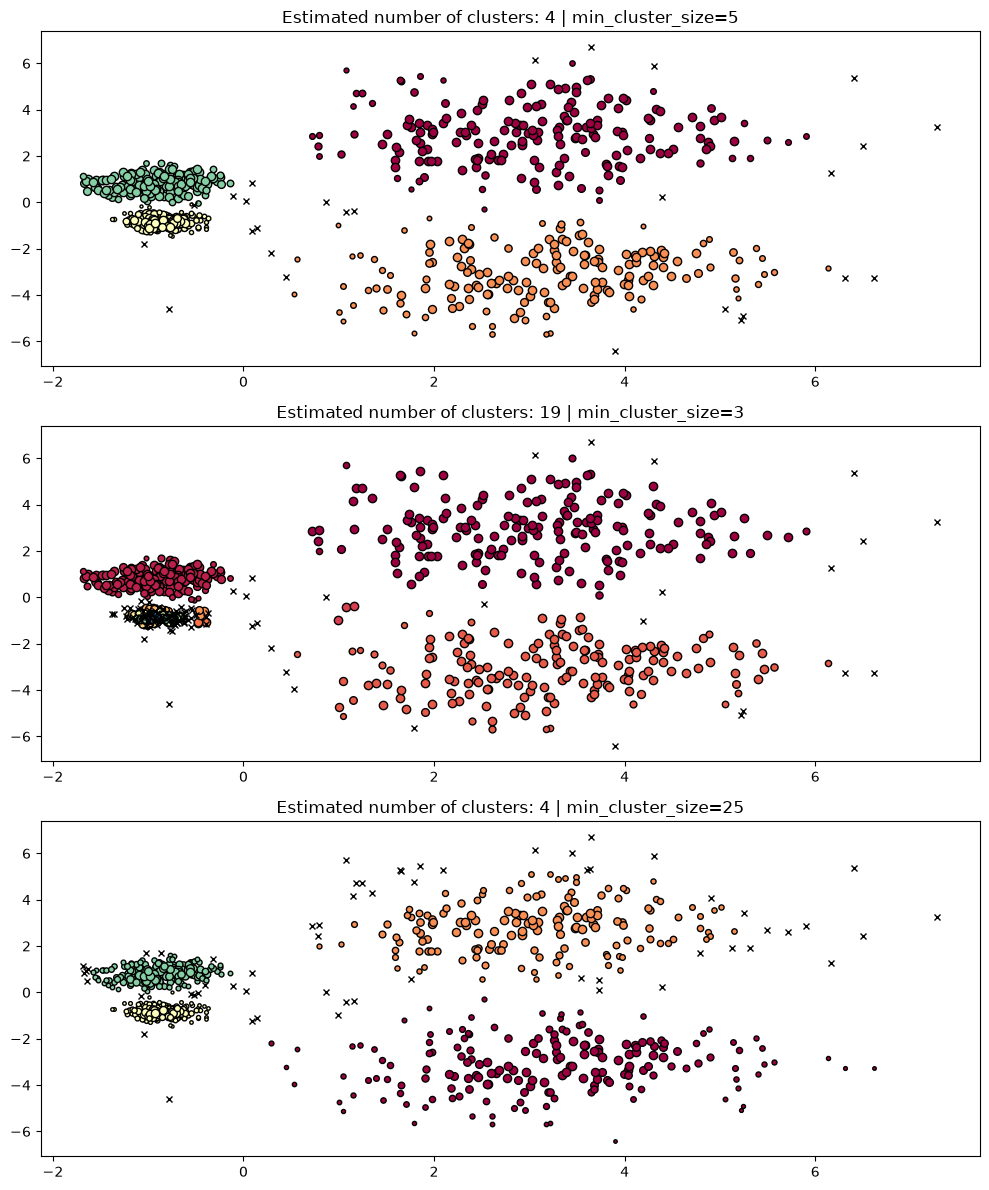

In [5]:
# Langkah 7: Eksperimen Hyperparameter min_cluster_size

PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

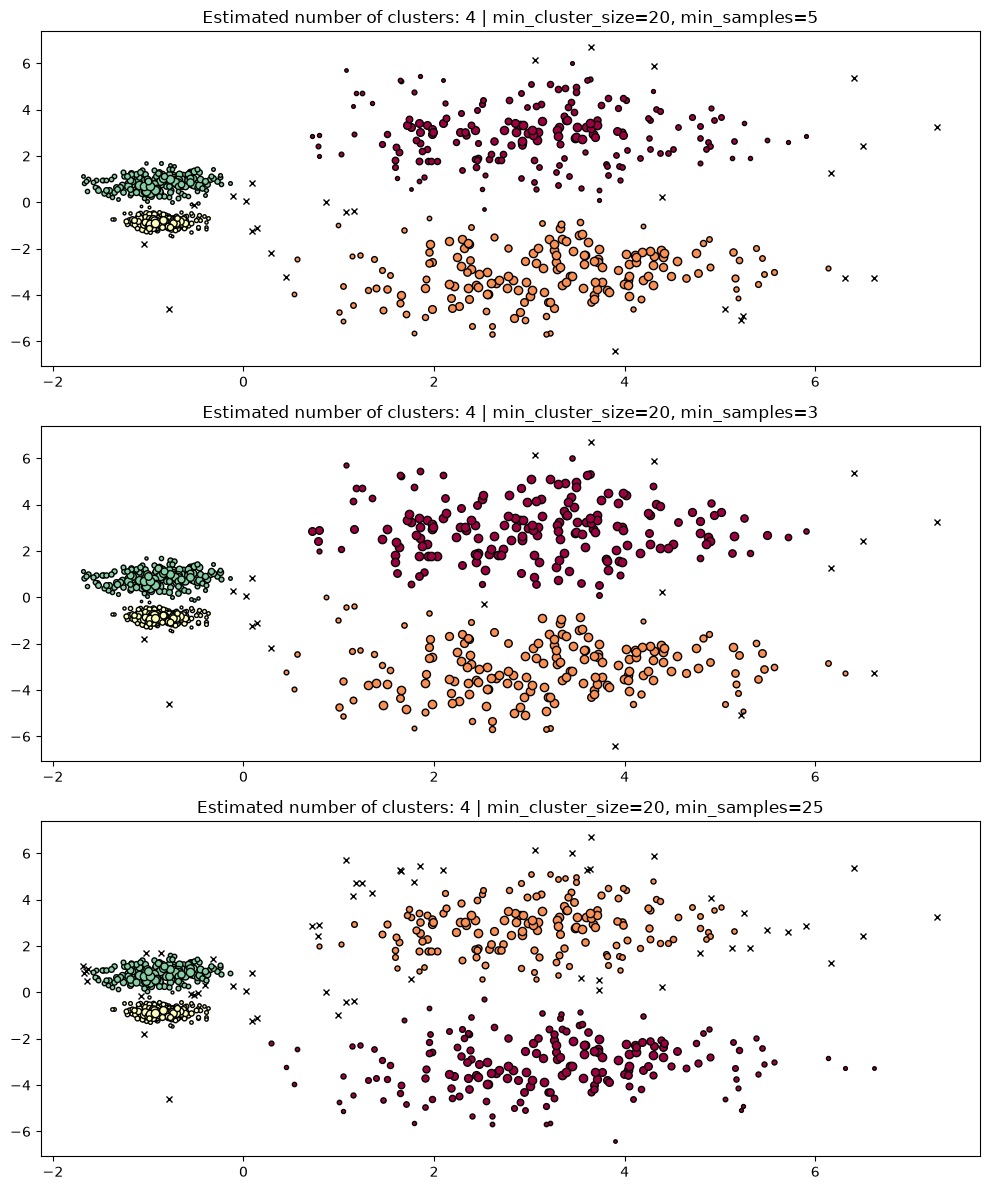

In [6]:
# Langkah 8: Eksperimen Hyperparameter min_samples

PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

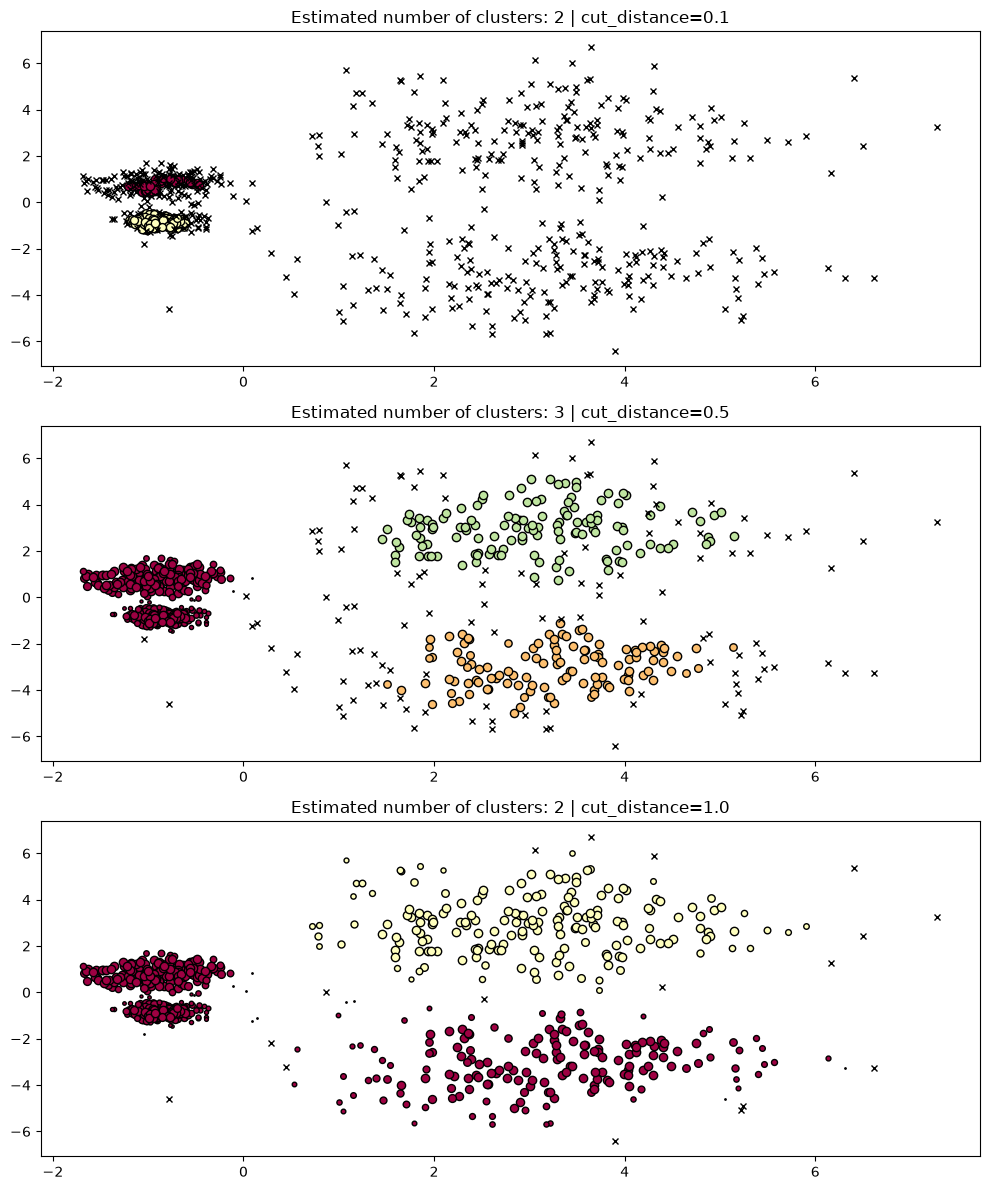

In [7]:
# Langkah 9: DBSCAN Clustering dari Pohon HDBSCAN

PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

In [8]:
# Langkah 10: Evaluasi dengan Silhouette Score

from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5743816709862986


In [9]:
# Langkah 11: Evaluasi dengan Davies-Bouldin Index

from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6436030674842073


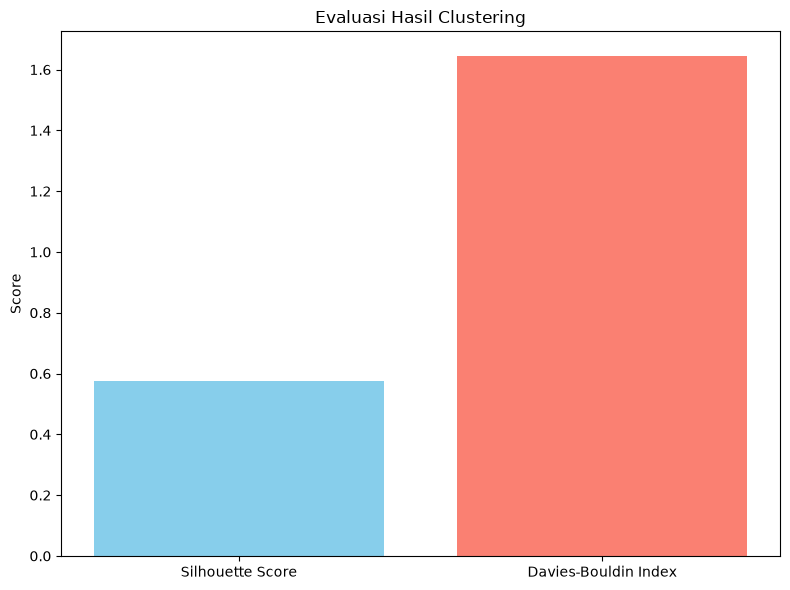

In [10]:
# Langkah 12: Visualisasi Hasil Evaluasi

# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()